# M13.12 — Dependencia de la red del escalón inicial (clic)

Pre-registro: `docs/experiments/M13_12_click_dependence.md` (4-11-2026), con la enmienda 1.

**Ejecutar una vez, de arriba abajo.** Regla de parada: una ejecución, sin reentrenamientos; si falla algún gate, se para.

## Pregunta
Si se elimina el clic y se deja todo lo demás idéntico (fuente, ruido, PSD, procesado), ¿cambian las predicciones y el RMSE de los modelos entrenados?

## Diseño
- 4000 filas de val, 400 por decil de τ30 (default_rng(131201)). Reconstrucción exacta.
- X_orig (igual a G3, gate G-REC) y X_noclick: la señal se sustituye por S, SEOBNRv4_opt desde 20 Hz con taper hasta 28 Hz, alineada con A en fase y tiempo (gates G-ALIGN y G-DIFF).
- Modelos: 4b-aug s123, 4a-aug s123 y 4a-aug s124. Gate: las predicciones sobre X_orig reproducen las guardadas en val, |Δ| ≤ 1e-3 en unidades estandarizadas (fp16).

## Medidas
Por grupo de τ (D1–D3, D4–D7, D8–D10), global y por etiqueta:
- ΔRMSE % (sin clic frente a con clic), con IC por bootstrap emparejado de filas (B = 2000, semilla 131202);
- desplazamiento medio de las predicciones (sin clic − con clic), relativo al RMSE;
- RMS del cambio de predicción, relativo al RMSE.

Descriptivo: relación del cambio de predicción con el SNR del clic.

## Criterio
- **Dependencia relevante:** en algún grupo y etiqueta, el límite inferior del IC de ΔRMSE es > +3 % o |desplazamiento medio| > 0,1 × RMSE (en cualquiera de los modelos). Consecuencia: la red usa el artefacto. La generación futura (G4) debe llevar taper antes de M14, y la lectura de los eventos reales debe revisarse.
- **Inocuo:** todos los IC de ΔRMSE dentro de ±3 % y todos los desplazamientos < 0,1 × RMSE. Se documenta; G4 lleva taper igualmente.
- **No concluyente:** el resto.

## No se puede concluir
- Cuánto se ganaría o perdería reentrenando sin clic.
- Nada sobre otras diferencias entre simulación y datos reales.
- Que una mejora sin clic implique mejor rendimiento en datos reales.

## Enmienda 1 (4-11-2026, antes de ver ninguna predicción)
G-ALIGN: la comparación de SNR del clic (alineado frente a fase maximizada) usa la tolerancia max(0,2 · SNR_phasemax; 0,3) en lugar de 0,2 relativo. Motivo: la ejecución abortó en la fila 405978 (D10, SNR del clic 0,16; residuo de fase ~1e-17; G-DIFF ~5e-13). Con clics casi nulos (filas truncadas, cuyo escalón cae fuera de la ventana final) la tolerancia relativa no es aplicable. La condición de fase no cambia.

In [1]:
# 1. Procedencia
import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root
# Read-only reuse, as in M13_8_seed_decomposition: pinned G1 contract.
from scripts.m12.m12_5_3_posthoc_check import LABELS, digest, load_contract, npz_to_physical, require

# (key, results tag): MODEL_TAGS of scripts/m13/m13_11_prepare_rows.py.
MODEL_SPECS = [
    ('4b_aug_s123', 'M13_4b_G3aug_s123'),
    ('4a_aug_s123', 'M13_4a_G3aug_s123'),
    ('4a_aug_s124', 'M13_4a_G3aug_s124'),
]
MODELS = [k for k, _ in MODEL_SPECS]
TAG = dict(MODEL_SPECS)
M_4B = '4b_aug_s123'
VARIANTS = ['orig', 'noclick']

cfg = json.loads((ROOT / 'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
M13_DIR = DATA_ROOT / 'results' / 'M13_3'
OUT_DIR = M13_DIR / 'M13_12'
BUILD_STAMP = '20261104T213820Z'
INPUTS_DIR = OUT_DIR / f'inputs_{BUILD_STAMP}'
PREDS_DIR = OUT_DIR / f'preds_{BUILD_STAMP}'
FIG_DIR = OUT_DIR / 'figures'
VAL_NPZ = 'val_predictions_embeddings.npz'
RUN_UTC = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')

# Pre-registered settings (doc M13.12).
N_BOOT = 2000
SEED = 131202
DRMSE_LIMIT = 3.0                  # %, ΔRMSE criterion
SHIFT_LIMIT = 0.1                  # |mean shift| / RMSE_orig criterion
REPRO_TOL = 1e-3                   # GATE: |pred_orig - pred_ref|, standardized units
N_ROWS, N_PER_DECILE = 4000, 400
# GATE y vs reference, physical units: same tolerances as m13_11_prepare_rows (absorb float32 inverse standardisation).
Y_RTOL, Y_ATOL = 1e-5, 1e-6
SPLIT_NAME = 'split_m13_12_val.npz'  # split file of the M13.12 predictions (m13_12_build_click_free.predict_configs)
CHUNK = 100                        # bootstrap replicates per vectorised block (memory only; does not change draws)

input_files = {name: INPUTS_DIR / name for name in ('selection.json', 'rows.json', 'gates.json')}
pred_files = {(m, v): PREDS_DIR / f'{m}_{v}_val_predictions_embeddings.npz' for m in MODELS for v in VARIANTS}
ref_files = {m: M13_DIR / TAG[m] / VAL_NPZ for m in MODELS}
all_files = {**{f'input/{k}': p for k, p in input_files.items()},
             **{f'pred/{m}/{v}': p for (m, v), p in pred_files.items()},
             **{f'ref/{m}': p for m, p in ref_files.items()}}
missing = [f'{k}: {p}' for k, p in all_files.items() if not p.exists()]
require(not missing, f'Missing files (required): {missing}')

sha = {k: digest(p) for k, p in all_files.items()}
prov = pd.DataFrame([dict(file=k, path=str(p), size_mb=p.stat().st_size / 2**20,
                          mtime_utc=datetime.fromtimestamp(p.stat().st_mtime, timezone.utc).isoformat(timespec='seconds'),
                          sha256_short=sha[k][:12]) for k, p in all_files.items()])

selection = json.loads(input_files['selection.json'].read_text())
rows_doc = json.loads(input_files['rows.json'].read_text())
build = json.loads(input_files['gates.json'].read_text())
require(build['verdict'] == 'PASS', f"Build gates.json verdict is {build['verdict']}")
require(build['first_failure'] is None and build['error'] is None, 'Build gates.json records a failure')
require(build['limit'] is None and selection['limit'] is None, 'Build ran with --limit: not the pre-registered 4000 rows')
require(build['n_rows_done'] == build['n_rows_todo'] == N_ROWS, f"Build rows: {build['n_rows_done']}/{build['n_rows_todo']}")
build_gates = {k: build[k] for k in ('verdict', 'n_rows_done', 'G_REC', 'G_ALIGN', 'G_DIFF', 'script_sha256')}

print(DATA_ROOT)
print('Run stamp:', RUN_UTC)
print('Build gates:', json.dumps(build_gates, indent=1))
prov

/data/vserrano/cbc_pe_data
Run stamp: 20261105T114640Z
Build gates: {
 "verdict": "PASS",
 "n_rows_done": 4000,
 "G_REC": {
  "threshold": 1e-05,
  "max_abs_dX_build": 0.0,
  "max_abs_dX_reprocess": 0.0,
  "n_fp16_diff_total": 0,
  "comparison": "X_orig (build_g1_row) and zscore(process_network(captured s + n)) vs G3 trainio X"
 },
 "G_ALIGN": {
  "residual_tol_rad": 0.01,
  "aligned_rel_tol": 0.2,
  "aligned_abs_tol": 0.3,
  "aligned_rule": "|aligned - phasemax| <= max(aligned_rel_tol * phasemax, aligned_abs_tol)",
  "max_abs_residual_rad": 0.009342547475416416,
  "max_aligned_rel_diff": 0.6626347870991368,
  "n_inconsistent": 0
 },
 "G_DIFF": {
  "threshold": 1e-06,
  "max_rel": 2.536834656517447e-12,
  "comparison": "max|(raw_orig - L(s_A)) - (raw_noclick - L(s_S))| / max|raw_orig - L(s_A)|, raw = process_network before the z-score, L = m13_11 process_clean"
 },
 "script_sha256": "b919f790273dafa4812cad17a1bb6c3fd8192d557b2c6b667bad962a9b033949"
}


,file,path,size_mb,mtime_utc,sha256_short
0,input/selection.json,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,1.256262,2026-11-04T21:38:20+00:00,e62be9fb9b0a
1,input/rows.json,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,3.709779,2026-11-04T22:10:22+00:00,0ea01348cfee
2,input/gates.json,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,5.862798,2026-11-04T22:10:21+00:00,f807bf095f85
3,pred/4b_aug_s123/orig,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,0.998339,2026-11-05T11:04:59+00:00,1f652001484b
4,pred/4b_aug_s123/noclick,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,0.998075,2026-11-05T11:05:14+00:00,1299fb18e1cf
5,pred/4a_aug_s123/orig,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,1.003314,2026-11-05T11:05:23+00:00,cf1beae3c114
6,pred/4a_aug_s123/noclick,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,1.003099,2026-11-05T11:05:32+00:00,d6944a07668c
7,pred/4a_aug_s124/orig,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,1.004941,2026-11-05T11:05:41+00:00,fa6244ecc72d
8,pred/4a_aug_s124/noclick,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,1.004983,2026-11-05T11:05:50+00:00,be70870d64b6
9,ref/4b_aug_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_4...,9.941967,2026-11-02T09:09:05+00:00,fcb174817f68


In [2]:
# 2. GATES (require aborts on the first failure)
paths, splits, c_mean, c_std, identity = load_contract(DATA_ROOT)
checks = ['frozen G1 contract (g1_npe_contract.load_contract)', 'build gates.json: PASS, no --limit, 4000 rows']


def check(ok, name):
    require(bool(ok), 'Check failed: ' + name)
    checks.append(name)


def load_pred(path, name, split_file, is_reference):
    # load_pred of M13_8 (cell 2): emb_val is never decompressed. Two differences: the expected split file is an argument,
    # and the mean(pred) vs mean(y) check runs on references only: on noclick it would abort on the effect under study;
    # on orig it is redundant with the reproduction gate. npz_to_physical decides the units from y alone.
    with np.load(path, allow_pickle=False) as a:
        y_raw = a['y_val']
        f, y = a['pred_val'].astype(np.float64), y_raw.astype(np.float64)
        idx = a['idx_val'].astype(np.int64)
        y_mean, y_std = a['y_mean'].astype(np.float64), a['y_std'].astype(np.float64)
        label_names = a['label_names'].tolist()
        split_name = Path(str(a['split_path'])).name
        ckpt_name = None if is_reference else Path(str(a['checkpoint_file'])).name
    n = len(idx)
    check(f.shape == y.shape == (n, 3), f'{name}: shapes')
    check(label_names == LABELS, f'{name}: label order {LABELS}')
    check(split_name == split_file, f'{name}: split_path is {split_file}')
    check(np.allclose(y_mean, c_mean, rtol=1e-6) and np.allclose(y_std, c_std, rtol=1e-6, atol=1e-8),
          f'{name}: npz y_mean/y_std equal M11 train-only label stats')
    check(len(np.unique(idx)) == n, f'{name}: idx without duplicates')
    check(np.isfinite(f).all() and np.isfinite(y).all(), f'{name}: finite values')
    y, f, units = npz_to_physical(y, f, c_mean, c_std)
    if is_reference:
        check(np.all(np.abs(f.mean(0) - y.mean(0)) < 0.1 * c_std), f'{name}: pred in units of y ({units})')
    ascending = bool(np.all(np.diff(idx) > 0))
    o = np.argsort(idx)                # align every file on the HDF5 row id
    return dict(f=f[o], y=y[o], y_raw=y_raw[o], idx=idx[o], units=units, ascending=ascending, ckpt=ckpt_name)


pred = {(m, v): load_pred(pred_files[(m, v)], f'{m}/{v}', SPLIT_NAME, False) for m in MODELS for v in VARIANTS}
ref = {m: load_pred(ref_files[m], f'ref/{m}', paths['split_file'].name, True) for m in MODELS}

# Row contract: rows.json is in ascending row id; selection.json is grouped by decile, so it is sorted here.
meta = pd.DataFrame(rows_doc['rows'])
sel = pd.DataFrame(selection['rows']).sort_values('row_index').reset_index(drop=True)
IDX = sel.row_index.to_numpy(np.int64)
check(len(IDX) == N_ROWS and len(np.unique(IDX)) == N_ROWS, f'selection.json: {N_ROWS} distinct rows')
check(rows_doc['label_names'] == LABELS, 'rows.json: label order')
check(np.array_equal(meta.row_index.to_numpy(np.int64), IDX), 'rows.json rows equal selection.json rows, ascending')
check(np.array_equal(meta.tau30_decile, sel.tau30_decile) and np.array_equal(meta.tau_group, sel.tau_group),
      'rows.json and selection.json agree on tau30_decile and tau_group')
check(np.isin(IDX, splits['val']).all(), 'selected rows belong to val')

# orig and noclick of every model: same idx_val, ascending in the file, equal to the selected rows.
Y_RAW_0 = pred[(MODELS[0], 'orig')]['y_raw']
for (m, v), p in pred.items():
    check(p['ascending'], f'{m}/{v}: idx_val ascending in the npz')
    check(np.array_equal(p['idx'], IDX), f'{m}/{v}: idx_val equals selection.json rows')
    check(p['ckpt'] == f'{TAG[m]}_final.pt', f'{m}/{v}: checkpoint is {TAG[m]}_final.pt')
    check(p['units'] == pred[(MODELS[0], 'orig')]['units'], f'{m}/{v}: same units as the first file')
    check(np.array_equal(p['y_raw'], Y_RAW_0), f'{m}/{v}: y_val identical to {MODELS[0]}/orig')

# Reproduction and y vs the stored val predictions, on the selected rows. Standardized = (physical - mean) / std with
# the train-only scaler, whatever the units stored in each npz.
repro = {}
for m in MODELS:
    r = ref[m]
    check(np.array_equal(r['idx'], np.sort(splits['val'])), f'ref/{m}: idx_val equals val membership')
    pos = np.searchsorted(r['idx'], IDX)
    check(np.array_equal(r['idx'][pos], IDX), f'ref/{m}: selected rows located')
    y_m = pred[(m, 'orig')]['y']
    dy = np.abs(y_m - r['y'][pos]).max(0)
    print(f'{m}: max |y - y_ref| (physical) =', dy)
    check(np.isclose(y_m, r['y'][pos], rtol=Y_RTOL, atol=Y_ATOL).all(), f'{m}: y_val equals reference y')
    dz = np.abs((pred[(m, 'orig')]['f'] - c_mean) / c_std - (r['f'][pos] - c_mean) / c_std).max(0)
    repro[m] = dict(zip(LABELS, map(float, dz)))
    print(f'{m}: max |pred_orig - pred_ref| (standardized) =', dz)
    check(np.all(dz <= REPRO_TOL), f'{m}: pred_orig reproduces reference (max |dz| <= {REPRO_TOL:g})')
    # A noclick npz predicted from the orig memmap would give a false 'inocuo'.
    check(not np.array_equal(pred[(m, 'orig')]['f'], pred[(m, 'noclick')]['f']), f'{m}: orig and noclick predictions differ')
print('GATE passed:', len(checks), 'checks')
pd.DataFrame(repro).T

4b_aug_s123: max |y - y_ref| (physical) = [0. 0. 0.]
4b_aug_s123: max |pred_orig - pred_ref| (standardized) = [1.54972076e-06 1.01327896e-06 8.49366188e-07]
4a_aug_s123: max |y - y_ref| (physical) = [0. 0. 0.]
4a_aug_s123: max |pred_orig - pred_ref| (standardized) = [2.38418579e-07 2.38418579e-07 3.57627869e-07]
4a_aug_s124: max |y - y_ref| (physical) = [0. 0. 0.]
4a_aug_s124: max |pred_orig - pred_ref| (standardized) = [2.14576721e-06 2.50339508e-06 1.37090683e-06]
GATE passed: 109 checks


,chirp_mass,total_mass,chi_eff
4b_aug_s123,1.549721e-06,1.013279e-06,8.493662e-07
4a_aug_s123,2.384186e-07,2.384186e-07,3.576279e-07
4a_aug_s124,2.145767e-06,2.503395e-06,1.370907e-06


In [3]:
# 3. Unidades físicas y grupos de tau
# npz_to_physical is already applied inside load_pred (cell 2), as in M13_8. Columns in LABELS order.
Y = pred[(MODELS[0], 'orig')]['y']
P = {m: {v: pred[(m, v)]['f'] for v in VARIANTS} for m in MODELS}
N = len(Y)

# Deciles and groups as stored by the build (tau30 of the true Mc, edges from the full val, M13_8 cell 3); not recomputed
# on the 4000 rows, where quantile edges would differ.
DEC = [f'D{d + 1}' for d in range(10)]
decile = meta.tau30_decile.to_numpy()
tau_group = meta.tau_group.to_numpy()
TAU_GROUPS = ['D1-D3', 'D4-D7', 'D8-D10']
check(list(selection['tau_groups']) == TAU_GROUPS, 'selection.json: tau groups are the pre-registered ones')
for name, ds in selection['tau_groups'].items():
    check(np.array_equal(tau_group == name, np.isin(decile, [DEC[d] for d in ds])), f'{name}: tau_group matches its deciles')
for k in DEC:
    check((decile == k).sum() == N_PER_DECILE, f'{k}: {N_PER_DECILE} rows')
GROUP_NAMES = TAU_GROUPS + ['global']
GROUPS = {**{k: tau_group == k for k in TAU_GROUPS}, 'global': np.ones(N, bool)}

snr_click = meta.snr_click_aligned_network.to_numpy(np.float64)   # network SNR of the click, aligned (not phase-maximised)
check(np.isfinite(snr_click).all() and np.all(snr_click >= 0), 'snr_click_aligned_network finite and non-negative')
print('n:', N, '| units in npz:', pred[(MODELS[0], 'orig')]['units'], '| group sizes:',
      {k: int(g.sum()) for k, g in GROUPS.items()})

n: 4000 | units in npz: standardized | group sizes: {'D1-D3': 1200, 'D4-D7': 1600, 'D8-D10': 1200, 'global': 4000}


In [4]:
# 4. Medidas pre-registradas con IC 95 % (bootstrap emparejado de filas)
def click_stats(fo, fc, y):
    # fo = pred orig, fc = pred noclick. Reduces over the last axis, so (replicates, rows) inputs give one value per
    # replicate. RMSE_orig of the same resample is the denominator of the relative measures.
    rmse_o = np.sqrt(np.mean((fo - y)**2, -1))
    rmse_c = np.sqrt(np.mean((fc - y)**2, -1))
    d = fc - fo
    return dict(rmse_orig=rmse_o, rmse_noclick=rmse_c, drmse_pct=100.0 * (rmse_c / rmse_o - 1.0),
                rel_shift=np.mean(d, -1) / rmse_o, rel_rms=np.sqrt(np.mean(d**2, -1)) / rmse_o)


rng = np.random.default_rng(SEED)        # single generator, consumed in this cell only, in the fixed order below


def boot(fn, arrays, rows):
    # boot of M13_8 (cell 4): one index draw per replicate, shared by every array (orig, noclick, y) and every quantity.
    xs = [a[rows] for a in arrays]
    n = len(xs[0])
    point = {k: float(v) for k, v in fn(*xs).items()}
    reps = {k: [] for k in point}
    for s in range(0, N_BOOT, CHUNK):
        ii = rng.integers(0, n, size=(min(CHUNK, N_BOOT - s), n))
        out = fn(*(x[ii] for x in xs))
        for k in reps:
            reps[k].append(out[k])
    return point, {k: np.concatenate(v) for k, v in reps.items()}


def ci(b):
    return np.percentile(b, [2.5, 97.5])


def rows_of(point, reps, **keys):
    return [dict(**keys, quantity=q, value=point[q], ci95_lo=ci(reps[q])[0], ci95_hi=ci(reps[q])[1],
                 n_nan=int(np.isnan(reps[q]).sum())) for q in point]


rows = []
for m in MODELS:
    for j, label in enumerate(LABELS):
        for k in GROUP_NAMES:
            g = GROUPS[k]
            pt, bt = boot(click_stats, [P[m]['orig'][:, j], P[m]['noclick'][:, j], Y[:, j]], g)
            rows += rows_of(pt, bt, model=m, label=label, group=k, n=int(g.sum()))
T = pd.DataFrame(rows)
check(T.n_nan.sum() == 0, 'bootstrap replicates without nan')
check(len(T) == 5 * len(MODELS) * len(LABELS) * len(GROUP_NAMES), 'measures: one row per quantity, model, label, group')


def table(q):
    t = T[T.quantity == q].copy()
    t['txt'] = [f'{v:+.3f} [{lo:+.3f}, {hi:+.3f}]' for v, lo, hi in zip(t.value, t.ci95_lo, t.ci95_hi)]
    w = t.pivot(index=['label', 'group'], columns='model', values='txt')
    return w.loc[pd.MultiIndex.from_product([LABELS, GROUP_NAMES]), MODELS]


with pd.option_context('display.width', 200, 'display.max_colwidth', None):
    display(table('drmse_pct'))

model                             4b_aug_s123                 4a_aug_s123                 4a_aug_s124
label      group                                                                                     
chirp_mass D1-D3   +37.648 [+30.935, +45.283]  +41.637 [+34.325, +49.774]  +44.255 [+37.020, +51.763]
           D4-D7   +17.339 [+14.006, +20.839]  +15.228 [+11.959, +18.744]  +15.465 [+12.403, +18.917]
           D8-D10  +30.153 [+21.760, +40.972]  +22.046 [+15.486, +30.424]  +24.361 [+16.707, +34.495]
           global  +28.400 [+25.007, +32.240]  +28.506 [+24.783, +32.373]  +30.099 [+26.207, +33.884]
total_mass D1-D3   +23.990 [+19.470, +28.720]  +26.367 [+21.545, +31.793]  +27.663 [+22.577, +33.203]
           D4-D7     +9.889 [+7.772, +12.197]     +7.642 [+5.605, +9.732]    +7.993 [+6.003, +10.006]
           D8-D10    +8.748 [+6.094, +11.977]     +6.244 [+4.281, +8.884]     +6.775 [+4.572, +9.730]
           global  +15.849 [+13.691, +18.111]  +15.804 [+13.676, +18.195]  +16.475 [+14.177, +18.783]
chi_eff    D1-D3   +30.233 [+26.639, +34.105]  +28.173 [+24.715, +31.638]  +28.213 [+24.955, +31.809]
           D4-D7      +3.741 [+1.708, +5.723]     +2.444 [+0.715, +4.234]     +2.981 [+1.114, +4.788]
           D8-D10     +2.161 [+1.410, +2.990]     +1.179 [+0.635, +1.743]     +1.563 [+0.893, +2.280]
           global  +12.619 [+11.024, +14.247]   +10.810 [+9.459, +12.257]   +11.310 [+9.921, +12.760]

In [5]:
# 5. Veredicto según el pre-registro
# Combinations = model x label x group, with 'global' included. The shift criterion uses the point estimate, as written
# in the pre-registration; its CI is reported but does not enter the decision.
KEYS = ['model', 'label', 'group']
dr = T[T.quantity == 'drmse_pct'].set_index(KEYS)
sh = T[T.quantity == 'rel_shift'].set_index(KEYS)

rel_drmse = dr.ci95_lo > DRMSE_LIMIT
rel_shift = sh.value.abs() > SHIFT_LIMIT
ok_drmse = (dr.ci95_lo >= -DRMSE_LIMIT) & (dr.ci95_hi <= DRMSE_LIMIT)
ok_shift = sh.value.abs() < SHIFT_LIMIT

if rel_drmse.any() or rel_shift.any():
    verdict = 'dependencia relevante'
    trig_drmse, trig_shift = dr[rel_drmse], sh[rel_shift]
elif ok_drmse.all() and ok_shift.all():
    verdict = 'inocuo'
    trig_drmse, trig_shift = dr[rel_drmse], sh[rel_shift]   # empty
else:
    verdict = 'no concluyente'
    trig_drmse, trig_shift = dr[~ok_drmse], sh[~ok_shift]   # what prevents 'inocuo'

COLS = ['value', 'ci95_lo', 'ci95_hi']
print('VEREDICTO:', verdict.upper())
print(f'{len(dr)} combinaciones | ΔRMSE: {len(trig_drmse)} disparan | desplazamiento: {len(trig_shift)} disparan')
with pd.option_context('display.width', 200, 'display.max_rows', None, 'display.float_format', '{:+.3f}'.format):
    print('\nΔRMSE % que disparan el veredicto:')
    print(trig_drmse[COLS] if len(trig_drmse) else '(ninguna)')
    print('\nDesplazamiento medio relativo que dispara el veredicto:')
    print(trig_shift[COLS] if len(trig_shift) else '(ninguna)')

VEREDICTO: DEPENDENCIA RELEVANTE
36 combinaciones | ΔRMSE: 30 disparan | desplazamiento: 22 disparan

ΔRMSE % que disparan el veredicto:
                                value  ci95_lo  ci95_hi
model       label      group                           
4b_aug_s123 chirp_mass D1-D3  +37.648  +30.935  +45.283
                       D4-D7  +17.339  +14.006  +20.839
                       D8-D10 +30.153  +21.760  +40.972
                       global +28.400  +25.007  +32.240
            total_mass D1-D3  +23.990  +19.470  +28.720
                       D4-D7   +9.889   +7.772  +12.197
                       D8-D10  +8.748   +6.094  +11.977
                       global +15.849  +13.691  +18.111
            chi_eff    D1-D3  +30.233  +26.639  +34.105
                       global +12.619  +11.024  +14.247
4a_aug_s123 chirp_mass D1-D3  +41.637  +34.325  +49.774
                       D4-D7  +15.228  +11.959  +18.744
                       D8-D10 +22.046  +15.486  +30.424
                       

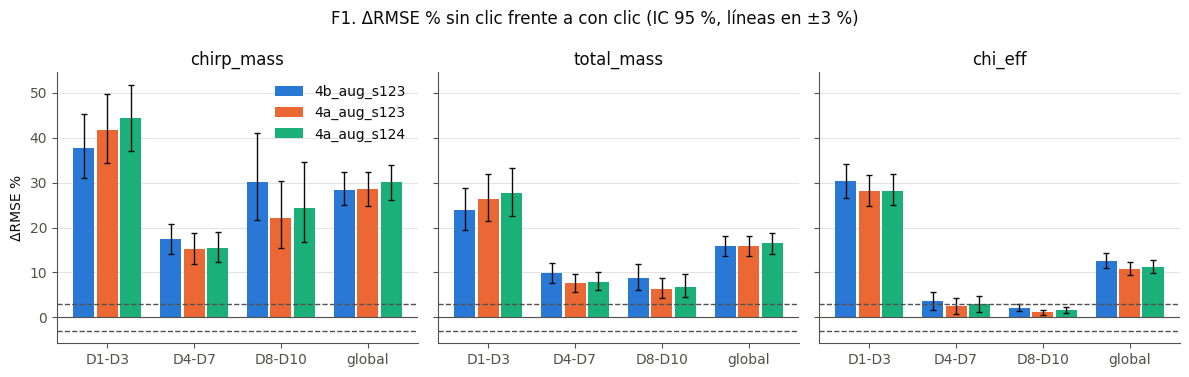

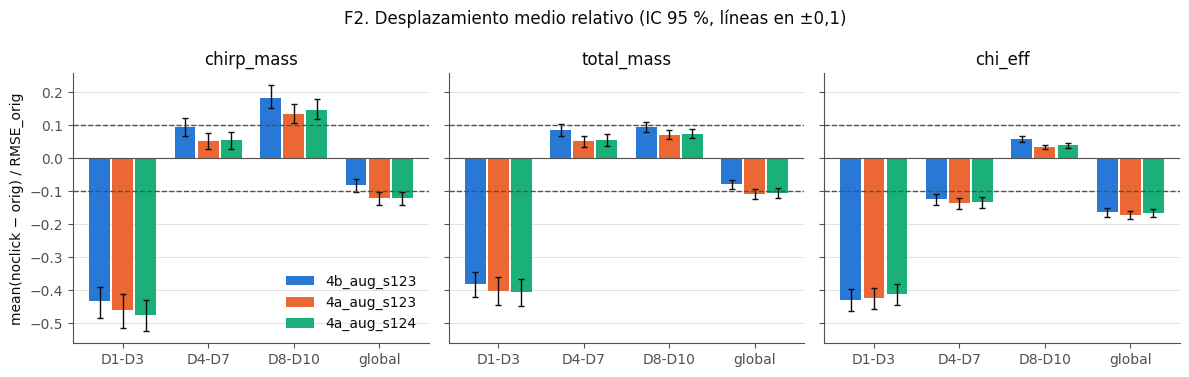

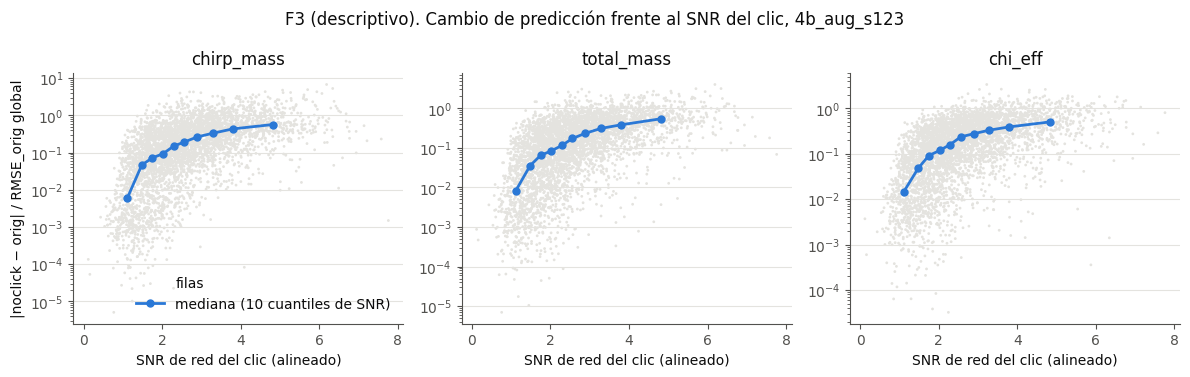

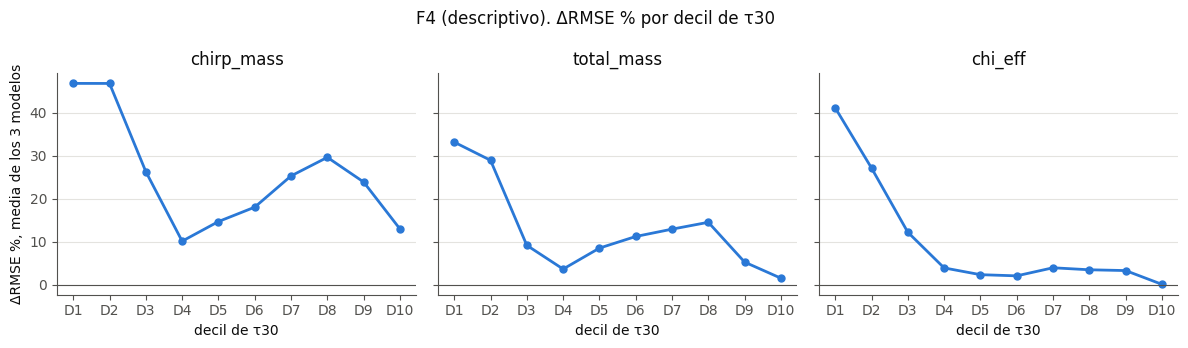

In [6]:
# 6. Figuras. Text in ink tones; model colours in a fixed order; a legend whenever there is more than one series.
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
COLORS = dict(zip(MODELS, ['#2a78d6', '#eb6834', '#1baf7a']))
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.grid.axis': 'y',
                     'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.edgecolor': MUTED,
                     'text.color': INK, 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'font.size': 10})
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig_paths = {}


def save(fig, stem):
    p = FIG_DIR / f'{stem}_{RUN_UTC}.png'
    with open(p, 'xb') as fh:          # never overwrites
        fig.savefig(fh, format='png', dpi=160, bbox_inches='tight')
    fig_paths[stem] = str(p)
    plt.show()


def group_bars(q, ylabel, limit, title, stem):
    fig, axes = plt.subplots(1, len(LABELS), figsize=(12, 3.8), sharey=True)
    x, w = np.arange(len(GROUP_NAMES)), 0.27
    for ax, label in zip(axes, LABELS):
        for i, m in enumerate(MODELS):
            t = T[(T.quantity == q) & (T.label == label) & (T.model == m)].set_index('group').loc[GROUP_NAMES]
            # A percentile CI need not contain the point estimate; negative lengths are invalid for yerr.
            yerr = np.clip(np.vstack([t.value - t.ci95_lo, t.ci95_hi - t.value]), 0, None)
            ax.bar(x + (i - 1) * w, t.value, w * 0.9, color=COLORS[m], label=m, yerr=yerr,
                   ecolor=INK, capsize=2, error_kw=dict(elinewidth=1))
        for s in (-limit, limit):
            ax.axhline(s, color=MUTED, ls='--', lw=1)
        ax.axhline(0, color=MUTED, lw=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels(GROUP_NAMES)
        ax.set_title(label)
    axes[0].set_ylabel(ylabel)
    axes[0].legend(frameon=False)
    fig.suptitle(title)
    fig.tight_layout()
    save(fig, stem)


group_bars('drmse_pct', 'ΔRMSE %', DRMSE_LIMIT, 'F1. ΔRMSE % sin clic frente a con clic (IC 95 %, líneas en ±3 %)',
           'F1_drmse_by_group')
group_bars('rel_shift', 'mean(noclick − orig) / RMSE_orig', SHIFT_LIMIT,
           'F2. Desplazamiento medio relativo (IC 95 %, líneas en ±0,1)', 'F2_shift_by_group')

# F3 (descriptive): 4b only. RMSE_orig is the global one of each label; bins are quantiles of the aligned click SNR.
fig, axes = plt.subplots(1, len(LABELS), figsize=(12, 3.8))
edges = np.quantile(snr_click, np.linspace(0, 1, 11))
snr_bin = np.clip(np.searchsorted(edges[1:-1], snr_click, side='right'), 0, 9)
x_med = np.array([np.median(snr_click[snr_bin == b]) for b in range(10)])
for j, (ax, label) in enumerate(zip(axes, LABELS)):
    rmse = np.sqrt(np.mean((P[M_4B]['orig'][:, j] - Y[:, j])**2))
    c = np.abs(P[M_4B]['noclick'][:, j] - P[M_4B]['orig'][:, j]) / rmse
    ax.scatter(snr_click, c, s=4, color=GRID, edgecolors='none', rasterized=True, label='filas')
    ax.plot(x_med, [np.median(c[snr_bin == b]) for b in range(10)], color=COLORS[M_4B], lw=2, marker='o', ms=5,
            label='mediana (10 cuantiles de SNR)')
    ax.set_yscale('log')
    ax.set_xlabel('SNR de red del clic (alineado)')
    ax.set_title(label)
axes[0].set_ylabel('|noclick − orig| / RMSE_orig global')
axes[0].legend(frameon=False)
fig.suptitle(f'F3 (descriptivo). Cambio de predicción frente al SNR del clic, {M_4B}')
fig.tight_layout()
save(fig, 'F3_change_vs_click_snr_4b')

# F4 (descriptive): per-decile ΔRMSE % of each model, then the mean of the three; no CI.
dec_rows = []
for m in MODELS:
    for j, label in enumerate(LABELS):
        for k in DEC:
            g = decile == k
            s = click_stats(P[m]['orig'][g, j], P[m]['noclick'][g, j], Y[g, j])
            dec_rows.append(dict(model=m, label=label, decile=k, drmse_pct=float(s['drmse_pct'])))
T_dec = pd.DataFrame(dec_rows)
dec_mean = T_dec.groupby(['label', 'decile']).drmse_pct.mean()
fig, axes = plt.subplots(1, len(LABELS), figsize=(12, 3.5), sharey=True)
for ax, label in zip(axes, LABELS):
    ax.plot(DEC, [dec_mean[(label, k)] for k in DEC], color=COLORS[MODELS[0]], lw=2, marker='o', ms=5)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xlabel('decil de τ30')
    ax.set_title(label)
axes[0].set_ylabel('ΔRMSE %, media de los 3 modelos')
fig.suptitle('F4 (descriptivo). ΔRMSE % por decil de τ30')
fig.tight_layout()
save(fig, 'F4_drmse_by_decile')

In [7]:
# 7. Tabla resumen y JSON
with pd.option_context('display.width', 200, 'display.max_colwidth', None, 'display.max_rows', None):
    for q in ('drmse_pct', 'rel_shift', 'rel_rms', 'rmse_orig', 'rmse_noclick'):
        print(q)
        display(table(q))

summary = dict(
    experiment='M13.12', pre_registration='docs/experiments/M13_12_click_dependence.md (with amendment 1)', run_utc=RUN_UTC,
    settings=dict(n_boot=N_BOOT, seed=SEED, ci='percentile 95 %', bootstrap='paired rows, unstratified within each group',
                  drmse_limit_pct=DRMSE_LIMIT, shift_limit=SHIFT_LIMIT, repro_tol_standardized=REPRO_TOL,
                  build_stamp=BUILD_STAMP, models=TAG, variants=VARIANTS, labels=list(LABELS), groups=GROUP_NAMES,
                  n_rows=N, snr_click='snr_click_aligned_network of rows.json', sha256=sha),
    gates=dict(build=build_gates, repro_max_abs_standardized=repro, n_checks=len(checks), checks=checks),
    measures=T.to_dict('records'),
    drmse_pct_by_decile=T_dec.to_dict('records'),
    verdict=verdict,
    triggers=dict(drmse_pct=trig_drmse.reset_index()[KEYS + COLS].to_dict('records'),
                  rel_shift=trig_shift.reset_index()[KEYS + COLS].to_dict('records')),
    figures=fig_paths,
)
summary_path = OUT_DIR / f'M13_12_summary_{RUN_UTC}.json'
with open(summary_path, 'x') as fh:    # never overwrites
    json.dump(summary, fh, indent=1, ensure_ascii=False)
print('VEREDICTO:', verdict.upper())
print(summary_path)

drmse_pct


model                             4b_aug_s123                 4a_aug_s123                 4a_aug_s124
label      group                                                                                     
chirp_mass D1-D3   +37.648 [+30.935, +45.283]  +41.637 [+34.325, +49.774]  +44.255 [+37.020, +51.763]
           D4-D7   +17.339 [+14.006, +20.839]  +15.228 [+11.959, +18.744]  +15.465 [+12.403, +18.917]
           D8-D10  +30.153 [+21.760, +40.972]  +22.046 [+15.486, +30.424]  +24.361 [+16.707, +34.495]
           global  +28.400 [+25.007, +32.240]  +28.506 [+24.783, +32.373]  +30.099 [+26.207, +33.884]
total_mass D1-D3   +23.990 [+19.470, +28.720]  +26.367 [+21.545, +31.793]  +27.663 [+22.577, +33.203]
           D4-D7     +9.889 [+7.772, +12.197]     +7.642 [+5.605, +9.732]    +7.993 [+6.003, +10.006]
           D8-D10    +8.748 [+6.094, +11.977]     +6.244 [+4.281, +8.884]     +6.775 [+4.572, +9.730]
           global  +15.849 [+13.691, +18.111]  +15.804 [+13.676, +18.195]  +16.475 [+14.177, +18.783]
chi_eff    D1-D3   +30.233 [+26.639, +34.105]  +28.173 [+24.715, +31.638]  +28.213 [+24.955, +31.809]
           D4-D7      +3.741 [+1.708, +5.723]     +2.444 [+0.715, +4.234]     +2.981 [+1.114, +4.788]
           D8-D10     +2.161 [+1.410, +2.990]     +1.179 [+0.635, +1.743]     +1.563 [+0.893, +2.280]
           global  +12.619 [+11.024, +14.247]   +10.810 [+9.459, +12.257]   +11.310 [+9.921, +12.760]

rel_shift


model                          4b_aug_s123              4a_aug_s123              4a_aug_s124
label      group                                                                            
chirp_mass D1-D3   -0.434 [-0.484, -0.391]  -0.462 [-0.515, -0.412]  -0.475 [-0.525, -0.430]
           D4-D7   +0.092 [+0.065, +0.120]  +0.050 [+0.025, +0.075]  +0.053 [+0.028, +0.078]
           D8-D10  +0.181 [+0.150, +0.220]  +0.133 [+0.106, +0.164]  +0.144 [+0.117, +0.178]
           global  -0.084 [-0.103, -0.064]  -0.122 [-0.142, -0.102]  -0.123 [-0.142, -0.104]
total_mass D1-D3   -0.382 [-0.421, -0.345]  -0.404 [-0.448, -0.360]  -0.407 [-0.449, -0.366]
           D4-D7   +0.084 [+0.065, +0.103]  +0.050 [+0.033, +0.067]  +0.053 [+0.036, +0.071]
           D8-D10  +0.093 [+0.078, +0.109]  +0.069 [+0.056, +0.083]  +0.073 [+0.060, +0.088]
           global  -0.081 [-0.095, -0.066]  -0.109 [-0.124, -0.095]  -0.106 [-0.121, -0.092]
chi_eff    D1-D3   -0.430 [-0.464, -0.397]  -0.426 [-0.459, -0.396]  -0.413 [-0.447, -0.381]
           D4-D7   -0.126 [-0.145, -0.109]  -0.138 [-0.155, -0.121]  -0.135 [-0.152, -0.119]
           D8-D10  +0.056 [+0.047, +0.065]  +0.031 [+0.025, +0.038]  +0.037 [+0.030, +0.045]
           global  -0.165 [-0.178, -0.152]  -0.172 [-0.185, -0.160]  -0.167 [-0.180, -0.155]

rel_rms


model                          4b_aug_s123              4a_aug_s123              4a_aug_s124
label      group                                                                            
chirp_mass D1-D3   +0.723 [+0.646, +0.806]  +0.767 [+0.678, +0.862]  +0.786 [+0.704, +0.876]
           D4-D7   +0.552 [+0.496, +0.611]  +0.509 [+0.455, +0.565]  +0.504 [+0.445, +0.568]
           D8-D10  +0.533 [+0.414, +0.666]  +0.444 [+0.346, +0.554]  +0.475 [+0.360, +0.607]
           global  +0.631 [+0.586, +0.679]  +0.630 [+0.582, +0.679]  +0.642 [+0.590, +0.692]
total_mass D1-D3   +0.561 [+0.508, +0.614]  +0.587 [+0.523, +0.650]  +0.597 [+0.534, +0.661]
           D4-D7   +0.401 [+0.366, +0.437]  +0.365 [+0.333, +0.399]  +0.367 [+0.331, +0.406]
           D8-D10  +0.266 [+0.214, +0.324]  +0.224 [+0.180, +0.274]  +0.233 [+0.180, +0.292]
           global  +0.455 [+0.428, +0.484]  +0.455 [+0.425, +0.490]  +0.460 [+0.429, +0.493]
chi_eff    D1-D3   +0.624 [+0.583, +0.672]  +0.607 [+0.571, +0.649]  +0.603 [+0.566, +0.644]
           D4-D7   +0.366 [+0.341, +0.390]  +0.346 [+0.324, +0.371]  +0.359 [+0.337, +0.383]
           D8-D10  +0.147 [+0.131, +0.163]  +0.110 [+0.097, +0.124]  +0.130 [+0.114, +0.148]
           global  +0.426 [+0.405, +0.449]  +0.402 [+0.383, +0.422]  +0.409 [+0.391, +0.429]

rmse_orig


model                           4b_aug_s123                4a_aug_s123               4a_aug_s124
label      group                                                                                
chirp_mass D1-D3    +5.619 [+5.225, +6.016]    +5.799 [+5.370, +6.265]   +5.653 [+5.276, +6.059]
           D4-D7    +4.760 [+4.504, +5.027]    +4.880 [+4.619, +5.140]   +4.797 [+4.546, +5.057]
           D8-D10   +3.127 [+2.655, +3.602]    +3.193 [+2.754, +3.682]   +3.081 [+2.653, +3.552]
           global   +4.633 [+4.430, +4.852]    +4.762 [+4.547, +4.990]   +4.652 [+4.456, +4.864]
total_mass D1-D3   +9.838 [+9.162, +10.599]  +10.247 [+9.453, +11.193]  +9.878 [+9.151, +10.755]
           D4-D7    +7.995 [+7.560, +8.438]    +8.204 [+7.814, +8.629]   +8.018 [+7.592, +8.419]
           D8-D10   +6.827 [+6.250, +7.431]    +7.031 [+6.460, +7.642]   +6.907 [+6.347, +7.479]
           global   +8.282 [+7.946, +8.652]    +8.558 [+8.205, +8.956]   +8.325 [+7.983, +8.688]
chi_eff    D1-D3    +0.166 [+0.158, +0.175]    +0.170 [+0.162, +0.177]   +0.167 [+0.159, +0.175]
           D4-D7    +0.150 [+0.144, +0.157]    +0.154 [+0.147, +0.160]   +0.151 [+0.144, +0.157]
           D8-D10   +0.164 [+0.154, +0.175]    +0.176 [+0.165, +0.188]   +0.169 [+0.159, +0.179]
           global   +0.160 [+0.155, +0.164]    +0.165 [+0.161, +0.171]   +0.161 [+0.157, +0.166]

rmse_noclick


model                             4b_aug_s123                 4a_aug_s123                 4a_aug_s124
label      group                                                                                     
chirp_mass D1-D3      +7.734 [+7.308, +8.172]     +8.213 [+7.736, +8.679]     +8.154 [+7.648, +8.650]
           D4-D7      +5.585 [+5.318, +5.854]     +5.623 [+5.357, +5.880]     +5.538 [+5.283, +5.815]
           D8-D10     +4.070 [+3.566, +4.571]     +3.897 [+3.436, +4.398]     +3.831 [+3.378, +4.332]
           global     +5.949 [+5.726, +6.190]     +6.119 [+5.869, +6.363]     +6.052 [+5.802, +6.295]
total_mass D1-D3   +12.198 [+11.552, +12.886]  +12.948 [+12.218, +13.763]  +12.610 [+11.867, +13.422]
           D4-D7      +8.785 [+8.361, +9.207]     +8.831 [+8.445, +9.241]     +8.659 [+8.244, +9.029]
           D8-D10     +7.424 [+6.807, +8.045]     +7.470 [+6.884, +8.091]     +7.375 [+6.816, +7.963]
           global     +9.594 [+9.250, +9.943]    +9.911 [+9.549, +10.293]    +9.696 [+9.352, +10.073]
chi_eff    D1-D3      +0.217 [+0.208, +0.225]     +0.217 [+0.209, +0.226]     +0.215 [+0.205, +0.223]
           D4-D7      +0.156 [+0.150, +0.162]     +0.157 [+0.151, +0.163]     +0.155 [+0.150, +0.161]
           D8-D10     +0.168 [+0.158, +0.178]     +0.178 [+0.167, +0.190]     +0.172 [+0.161, +0.182]
           global     +0.180 [+0.175, +0.184]     +0.183 [+0.178, +0.189]     +0.180 [+0.175, +0.184]

VEREDICTO: DEPENDENCIA RELEVANTE
/data/vserrano/cbc_pe_data/results/M13_3/M13_12/M13_12_summary_20261105T114640Z.json
